In [1]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import os
import torch
from torchvision import transforms
import onnxruntime 
import time
import openvino as ov
import ipywidgets as widgets
import sys


## 1.torch转换成onnx

In [5]:
sys.path.insert(0,"../")

In [6]:
model = torch.load('/mnt/bb/yc/virtual-tryon-ds/checkpoint/pf_b_2l2e-05m_35/pf_b_2l2e-05m_35_data.pt',map_location='cpu')

In [7]:
device = "cpu"
model = model.to(device)

input_clothes = torch.ones(1,3,256,192).to(device)
input_person = torch.ones(1,3,256,192).to(device)

print(input_clothes.shape)
print(input_person.shape)

torch.Size([1, 3, 256, 192])
torch.Size([1, 3, 256, 192])


In [8]:

dummy_output = model(input_clothes,input_person)


/mnt/zz/anaconda3/envs/torch2.0/lib/python3.8/site-packages/torch/functional.py:507: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3549.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
/mnt/zz/anaconda3/envs/torch2.0/lib/python3.8/site-packages/torch/nn/functional.py:4316: UserWarning: Default grid_sample and affine_grid behavior has changed to align_corners=False since 1.3.0. Please specify align_corners=True if the old behavior is desired. See the documentation of grid_sample for details.
  warnings.warn(


In [6]:
print(model)

NPDNet(
  (source_features): FeatureEncoder(
    (encoders): ModuleList(
      (0): Sequential(
        (0): DownSample(
          (block): Sequential(
            (0): BatchNorm2d(3, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (1): ReLU(inplace=True)
            (2): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
          )
        )
        (1): ResBlock(
          (block): Sequential(
            (0): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (1): ReLU(inplace=True)
            (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          )
        )
      )
      (1): Sequential(
        (0): DownSample(
          (block): Sequential(
            (0): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (1): ReLU(inplace=True)
            (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(

In [6]:
#自建立一个grid_sampler函数
# from torch.onnx import register_custom_op_symbolic
# import torch.onnx.symbolic_helper as sym_help

# def grid_sampler(g, input, grid, mode, padding_mode, align_corners):
#     # mode
#     #   'bilinear'      : onnx::Constant[value={0}]
#     #   'nearest'       : onnx::Constant[value={1}]
#     #   'bicubic'       : onnx::Constant[value={2}]
#     # padding_mode
#     #   'zeros'         : onnx::Constant[value={0}]
#     #   'border'        : onnx::Constant[value={1}]
#     #   'reflection'    : onnx::Constant[value={2}]
#     mode = sym_help._maybe_get_const(mode, "i")
#     padding_mode = sym_help._maybe_get_const(padding_mode, "i")
#     mode_str = ['bilinear', 'nearest', 'bicubic'][mode]
#     padding_mode_str = ['zeros', 'border', 'reflection'][padding_mode]
#     align_corners = int(sym_help._maybe_get_const(align_corners, "b"))

#     return g.op("com.microsoft::GridSample", input, grid,
#                 mode_s=mode_str,
#                 padding_mode_s=padding_mode_str,
#                 align_corners_i=align_corners)
    
# register_custom_op_symbolic('::grid_sampler', grid_sampler, 1)

In [7]:
# #跟踪法转ir
# traced_model = torch.jit.trace(model, (source_image,ref_image))
# # torch.onnx.export(traced_model, (source_image,ref_image), "pf_b_2l2e-05m_35_data.onnx",opset_version=11,input_names=['source_image', 'ref_image'], 
#         # output_names=['output'],verbose=True)


In [8]:
# #记录法转ir
# model_script = torch.jit.script(model)
# torch.onnx.export(model_script, (source_image,ref_image), f'{model_name}_script.onnx', example_outputs=dummy_output) 

In [78]:
#转onnx
torch.onnx.export(model,(input_person,input_clothes),"pf_b_2l2e-05m_35_data.onnx",opset_version=16,input_names=['input_person','input_clothes'], 
        output_names=['output'])

/mnt/bb/yc/virtual-tryon-ds/models/never_parse_ds_studentmodel.py:205: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if return_all:
/mnt/zz/anaconda3/envs/torch2.0/lib/python3.8/site-packages/torch/nn/functional.py:4316: UserWarning: Default grid_sample and affine_grid behavior has changed to align_corners=False since 1.3.0. Please specify align_corners=True if the old behavior is desired. See the documentation of grid_sample for details.
  warnings.warn(
/mnt/bb/yc/virtual-tryon-ds/models/never_parse_ds_studentmodel.py:262: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize 

In [12]:
# #转换测试代码
# import numpy as np

# # 原始数组形状
# ref_image_np_shape = (256, 192, 3)

# # 将形状转换为 [1, 3, 256, 192]
# new_shape = [1] + list(ref_image_np_shape[::-1])
# print("new_shape:",new_shape)
# # 创建一个随机的形状为 (256, 192, 3) 的 NumPy 数组作为示例
# ref_image_np = np.random.rand(*ref_image_np_shape)
# print("ref_image_np:",ref_image_np.shape)
# # 转换形状
# ref_image_np_reshaped = np.transpose(ref_image_np, (2, 0, 1)).reshape(new_shape)

# print(ref_image_np_reshaped.shape)

In [9]:
#由于没有对数据预处理，当直接输入图片时，导致无法得到理想结果，因此对数据进行预处理，预处理的方法需要自己的源码中所使用的方法。
#输入预处理
load_width = 192
input_clothes = Image.open("/mnt/bb/yc/virtual-tryon-ds/data/VITON/VITON/VITON_test/clothes/000010_1.jpg").convert('RGB')
input_person = Image.open("/mnt/bb/yc/virtual-tryon-ds/data/VITON/VITON/VITON_test/test_img/000228_0.jpg").convert('RGB')
plt_clothes = input_clothes #拷贝一份，用于之后绘制图像
plt_person = input_person
transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
        ])
input_clothes = transforms.Resize(load_width, interpolation=2)(input_clothes)
input_person = transforms.Resize(load_width, interpolation=2)(input_person)
input_clothes = transform(input_clothes).unsqueeze(0)  #torch.Size([1,3, 256, 192])
input_person = transform(input_person).unsqueeze(0)#torch.Size([1,3, 256, 192])

input_clothes_np = np.array(input_clothes).astype(np.float32)
input_person_np = np.array(input_person).astype(np.float32)



In [8]:
print(input_clothes.shape)
print(input_person.shape)
print(input_clothes_np.shape)
print(input_person_np.shape)


torch.Size([1, 3, 256, 192])
torch.Size([1, 3, 256, 192])
(1, 3, 256, 192)
(1, 3, 256, 192)


In [11]:

#onnx推理模型
ort_session = onnxruntime.InferenceSession("./pf_b_2l2e-05m_35_data.onnx")
start_time = time.time()
ort_inputs = {'input_clothes': input_clothes_np,'input_person':input_person_np}
# ort_inputs = {'input_clothes': source_image_np,'input_person':ref_image_np} 
ort_output = ort_session.run(['output'], ort_inputs)[0] 
end_time = time.time()
# 计算并打印运行时间
execution_time = end_time - start_time
print(f"Execution time: {execution_time:.4f} seconds")  # 


Execution time: 0.8782 seconds


In [12]:
#对onnx输出处理
value_range = (np.min(ort_output),np.max(ort_output)) #此处进行归一化
onnx_output_result = ((ort_output - value_range[0]) / (value_range[1] - value_range[0])) * 255
onnx_output_result = onnx_output_result.astype(np.uint8)  # 将数据转换为 uint8

onnx_output_result = np.transpose(onnx_output_result, (2, 3, 1, 0))
print(onnx_output_result.shape)

onnx_output_result = np.squeeze(onnx_output_result)
print(onnx_output_result.shape)
# onnx_output_result = np.transpose(onnx_output_result, (1, 2, 0))


(256, 192, 3, 1)
(256, 192, 3)


(-0.5, 191.5, 255.5, -0.5)

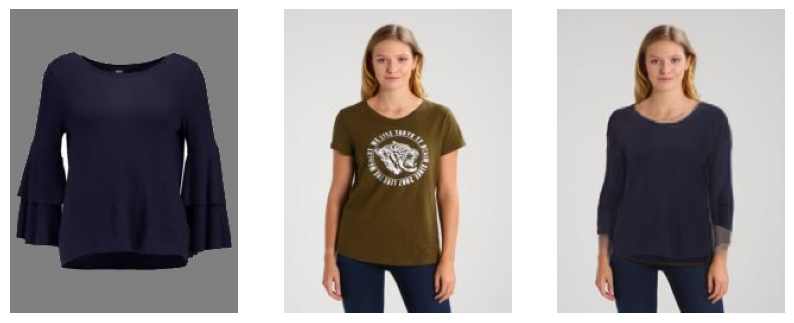

In [13]:
# 可视化
fig, axes = plt.subplots(1, 3, figsize=(10, 5))
# 转换为numpy对象
plt_clothes_np = np.array(plt_clothes)
plt_person_np = np.array(plt_person)


# 在第一个子图上显示衣服图像
axes[0].imshow(plt_clothes_np)
axes[0].axis('off')

# 在第二个子图上显示人物图像
axes[1].imshow(plt_person_np)
axes[1].axis('off')

axes[2].imshow(onnx_output_result)
axes[2].axis('off')


In [14]:
#对原模型的时间进行统计
start_time = time.time()
ori_output = model(input_person,input_clothes)
end_time = time.time()
# 计算并打印运行时间
execution_time = end_time - start_time
print(f"Execution time: {execution_time:.4f} seconds")  #

Execution time: 0.9784 seconds


In [15]:
# print(ori_output)
#对onnx输出处理
print(ori_output.size())
ori_output_np = np.array(ori_output.detach())
value_range = (np.min(ori_output_np),np.max(ori_output_np)) #此处进行归一化
ori_output_result = ((ori_output_np - value_range[0]) / (value_range[1] - value_range[0])) * 255
ori_output_result = ori_output_result.astype(np.uint8)  # 将数据转换为 uint8

ori_output_result = np.transpose(ori_output_result, (2, 3, 1, 0))
print(ori_output_result.shape)

ori_output_result = np.squeeze(ori_output_result)
print(ori_output_result.shape)
# ori_output_result = np.transpose(ori_output_result, (1, 2, 0))

torch.Size([1, 3, 256, 192])
(256, 192, 3, 1)
(256, 192, 3)


(-0.5, 191.5, 255.5, -0.5)

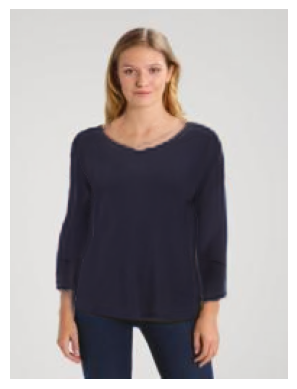

In [16]:
plt.imshow(ori_output_result)
plt.axis('off')

(-0.5, 191.5, 255.5, -0.5)

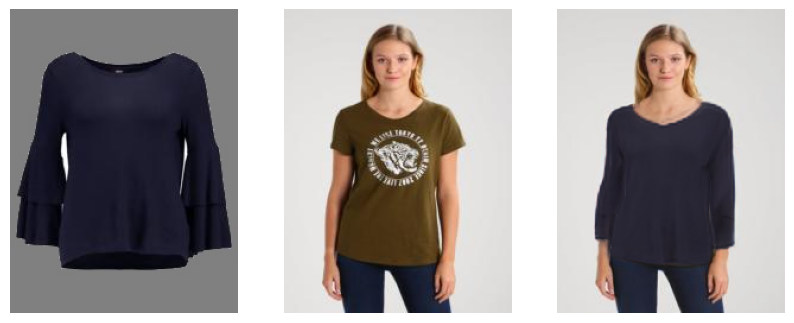

In [17]:
# 整体对比
# 可视化
fig, axes = plt.subplots(1, 3, figsize=(10, 5))
# 转换为numpy对象
plt_clothes_np = np.array(plt_clothes)
plt_person_np = np.array(plt_person)


# 在第一个子图上显示衣服图像
axes[0].imshow(plt_clothes_np)
axes[0].axis('off')

# 在第二个子图上显示人物图像
axes[1].imshow(plt_person_np)
axes[1].axis('off')

axes[2].imshow(onnx_output_result)
axes[2].axis('off')

plt.imshow(ori_output_result)
plt.axis('off')

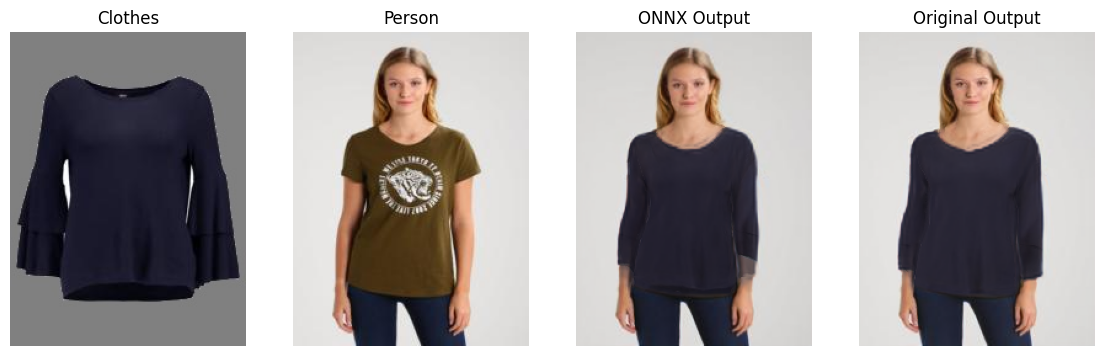

In [141]:
# 图像标注名字
names = ['Clothes', 'Person', 'ONNX Output', 'Original Output']

# 整体对比可视化
fig, axes = plt.subplots(1, 4, figsize=(14, 5))



# 在子图上显示图像并标注名字
for i, (img, name) in enumerate(zip([plt_clothes_np, plt_person_np, onnx_output_result, ori_output_result], names)):
    axes[i].imshow(img)
    axes[i].axis('off')
    axes[i].set_title(name)

plt.show()

In [19]:
#两模型速度检测
epoch = 30
start_time = time.time()
for i in range(epoch):
    ort_inputs = {'input_clothes': input_clothes_np,'input_person':input_person_np}
    ort_output = ort_session.run(['output'], ort_inputs)[0] 
end_time = time.time()
execution_time = end_time-start_time
print(f"onnx model Execution time: {execution_time/epoch:.4f} seconds. FPS:{epoch/execution_time:.4f}")

start_time = time.time()
for i in range(epoch):
    ori_output = model(input_person,input_clothes)
end_time = time.time()
execution_time = end_time-start_time

print(f"original model Execution time: {execution_time/epoch:.4f} seconds. FPS:{epoch/execution_time:.4f}")

onnx model Execution time: 0.7005 seconds. FPS:1.4276


/mnt/zz/anaconda3/envs/torch2.0/lib/python3.8/site-packages/torch/nn/functional.py:4316: UserWarning: Default grid_sample and affine_grid behavior has changed to align_corners=False since 1.3.0. Please specify align_corners=True if the old behavior is desired. See the documentation of grid_sample for details.
  warnings.warn(


original model Execution time: 0.7390 seconds. FPS:1.3532


In [155]:
import os

# 文件路径
onnx_model_path = "/mnt/bb/yc/virtual-tryon-ds/pf_b_2l2e-05m_35_data.onnx"
ori_model_path = "/mnt/bb/yc/virtual-tryon-ds/checkpoint/pf_b_2l2e-05m_35/pf_b_2l2e-05m_35_data.pt"

# 获取文件大小并转换为 MB
onnx_model_size_mb = os.path.getsize(onnx_model_path) / (1024 * 1024)
ori_model_size_mb = os.path.getsize(ori_model_path) / (1024 * 1024)

print(f"ONNX     模型大小：{onnx_model_size_mb:.1f} MB")
print(f"original 模型大小：{ori_model_size_mb:.1f} MB")


ONNX     模型大小：34.8 MB
original 模型大小：34.7 MB


## CPU推理性能对比

| 模型       | 大小   | 速度     |FPS|
|------------|--------|----------|---|
| onnx_model | 34.8MB | 0.6217ms |1.4276|
| ori_model  | 34.7MB  | 0.6688ms |1.3532|
